# CR3BP Starter Notebook — QPIT Project

**Project:** Supervised Learning for Quasi-Periodic Invariant Torus Identification and Classification in the Earth-Moon CR3BP

**Author:** _your name here_

**Week:** 1–2 — building the dynamical systems foundation

---

## Where this notebook fits in the project

The end goal of this project is to train a neural network that identifies whether an arbitrary initial condition in the Earth-Moon CR3BP lies on a quasi-periodic invariant torus (QPIT). To get there, you need to climb a ladder of dynamical structures, from simplest to most complex:

1. **CR3BP equations of motion** — the foundation. *(This notebook.)*
2. **Lagrange points** — the five equilibrium points of the system. *(This notebook.)*
3. **Periodic orbits** — closed-loop trajectories around the Lagrange points (Lyapunov orbits, halo orbits). *(Phase 2, Weeks 4–6.)*
4. **Invariant manifolds of periodic orbits** — the stable/unstable "tubes" around periodic orbits. *(Phase 2, Week 6.)*
5. **Quasi-periodic invariant tori** — 2D surfaces in phase space, computed via Fourier-Galerkin or collocation. *(Phase 3, Weeks 7–10.)*
6. **ML on QPIT data** — the core research contribution. *(Phase 4, Weeks 11–13.)*

This notebook gets you through rungs 1 and 2. By the time you finish it, you will have a validated CR3BP integrator and all five Lagrange points located numerically. Everything else in the project builds on what you do here.

## What this notebook does NOT do

It does not contain any QPIT computation, any periodic orbits, any manifolds, or any ML. Those are yours to build over the next 20 weeks. The TODOs at the bottom of the notebook are stepping stones from here to where you need to be.

## Required environment

```
python>=3.11
numpy
scipy
matplotlib
jupyter
```

Already installed in your venv if you completed the environment setup.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# For reproducibility of any future stochastic experiments
RNG_SEED = 42
np.random.seed(RNG_SEED)

## 1. The CR3BP setup

The **Circular Restricted Three-Body Problem (CR3BP)** describes the motion of a massless body (e.g., a spacecraft) in the gravitational field of two primary bodies that orbit their common center of mass in circular orbits.

We work in a **rotating frame** that co-rotates with the primaries, so the primaries appear stationary. We use canonical normalization:

- **Mass parameter:** $\mu = m_2 / (m_1 + m_2)$ where $m_1 \geq m_2$
- **Distance:** Earth-Moon distance set to 1
- **Time:** scaled so the Moon's orbital period is $2\pi$
- **Primary 1 (Earth)** sits at $(-\mu, 0)$
- **Primary 2 (Moon)** sits at $(1-\mu, 0)$

### Equations of motion (planar case)

State vector: $\mathbf{s} = [x, y, \dot{x}, \dot{y}]^T$.

Let $r_1 = \sqrt{(x+\mu)^2 + y^2}$ and $r_2 = \sqrt{(x-1+\mu)^2 + y^2}$ be the distances to the two primaries. Then:

$$\ddot{x} = 2\dot{y} + x - \frac{(1-\mu)(x+\mu)}{r_1^3} - \frac{\mu(x-1+\mu)}{r_2^3}$$

$$\ddot{y} = -2\dot{x} + y - \frac{(1-\mu)y}{r_1^3} - \frac{\mu y}{r_2^3}$$

The Coriolis terms $\pm 2\dot{q}$ come from the rotating frame; the rest is two-body gravity plus the centrifugal term hidden in $x$ and $y$.

### Why we start here

The CR3BP equations are the substrate for *everything* in this project. The Lagrange points are equilibria of these equations. Periodic orbits are bounded solutions of these equations. Invariant tori are surfaces in the phase space defined by these equations, on which trajectories of these equations evolve quasi-periodically. We need this code to work reliably and accurately, or nothing downstream will.

**References:**
- Koon, Lo, Marsden, Ross, *Dynamical Systems, the Three-Body Problem and Space Mission Design*, Chapter 3.
- Olikara 2016 PhD thesis, Chapter 2 (background).

In [2]:
# Earth-Moon mass parameter
# μ = M_moon / (M_earth + M_moon), from JPL DE441 mass ratios
MU_EARTH_MOON = 0.01215058560962404


def cr3bp_rhs(t, state, mu):
    """Right-hand side of the planar CR3BP equations of motion.

    Parameters
    ----------
    t : float
        Time (unused — system is autonomous, but solve_ivp requires this signature).
    state : array_like, shape (4,)
        State vector [x, y, vx, vy] in the rotating frame.
    mu : float
        Mass parameter μ = m2 / (m1 + m2).

    Returns
    -------
    list of length 4
        Time derivative of the state: [vx, vy, ax, ay].
    """
    x, y, vx, vy = state

    # Distances to primaries
    r1 = np.sqrt((x + mu) ** 2 + y ** 2)
    r2 = np.sqrt((x - 1 + mu) ** 2 + y ** 2)

    # Accelerations
    ax = 2 * vy + x - (1 - mu) * (x + mu) / r1 ** 3 - mu * (x - 1 + mu) / r2 ** 3
    ay = -2 * vx + y - (1 - mu) * y / r1 ** 3 - mu * y / r2 ** 3

    return [vx, vy, ax, ay]

## 2. The Jacobi constant

The CR3BP has no general analytic solution — this is part of why it's chaotic. But it does have one conserved quantity, the **Jacobi constant** $C$:

$$C(x, y, \dot{x}, \dot{y}) = 2\Omega(x, y) - (\dot{x}^2 + \dot{y}^2)$$

where the effective potential is

$$\Omega(x, y) = \frac{1}{2}(x^2 + y^2) + \frac{1-\mu}{r_1} + \frac{\mu}{r_2}$$

For any true trajectory, $C$ stays exactly constant. Numerically it won't be exact — but with a high-order integrator at tight tolerances, it should be conserved to about machine epsilon over the integration window.

### Why we care about $C$ for QPITs

This is the connection to the rest of the project. **QPITs come in families parameterized by Jacobi constant.** When Olikara's thesis and Baresi's papers talk about "computing a family of tori," they mean: pick a Jacobi constant value, find all the QPITs at that energy. Then change $C$ slightly and continue the family. Without a Jacobi constant that's conserved to high precision in your integrator, you can't even define which torus family you're working with — your "trajectory at $C = 3.05$" would actually drift to $C = 3.06$ over time.

So this isn't just a nice physics fact. **Jacobi conservation to ~$10^{-10}$ is a prerequisite for the entire project.** If your integrator can't deliver that, the rest of the work is on sand.

In [3]:
def jacobi_constant(state, mu):
    """Compute the Jacobi constant for a state in the planar CR3BP.

    The Jacobi constant is the only known integral of motion for this system
    and is therefore our primary diagnostic for integrator correctness.
    It is also the parameter that labels families of QPITs in this project.

    Parameters
    ----------
    state : array_like, shape (4,)
        State vector [x, y, vx, vy].
    mu : float
        Mass parameter.

    Returns
    -------
    float
        The Jacobi constant. Conserved along any true trajectory.
    """
    x, y, vx, vy = state
    r1 = np.sqrt((x + mu) ** 2 + y ** 2)
    r2 = np.sqrt((x - 1 + mu) ** 2 + y ** 2)
    omega = 0.5 * (x ** 2 + y ** 2) + (1 - mu) / r1 + mu / r2
    return 2 * omega - (vx ** 2 + vy ** 2)

## 3. The five Lagrange points

The CR3BP has five equilibrium points (places where a spacecraft could in principle sit at rest in the rotating frame):

- **L1, L2, L3** lie on the x-axis (collinear with the two primaries) and are dynamically **unstable**. Periodic orbits and QPITs around these points are central to mission design (the Lunar Gateway lives in this regime).
- **L4 and L5** form equilateral triangles with the two primaries. For mass ratios with $\mu < 0.0385$ (true for Earth-Moon and Sun-Earth), they are **dynamically stable**.

For your project, L1 and L2 are the most important — most QPIT research is done around L1 and L2 because the periodic orbits there are mission-relevant (cislunar Gateway, Sun-Earth L2 observatories like JWST).

The collinear points satisfy a polynomial equation that we solve via bracketed root-finding. The triangular points have closed-form positions at $(\frac{1}{2} - \mu, \pm\frac{\sqrt{3}}{2})$.

In [4]:
def find_lagrange_points(mu):
    """Locate all five Lagrange points for a given mass parameter.

    Uses bracketed root-finding (brentq) for the three collinear points;
    L4 and L5 are given analytically.

    Parameters
    ----------
    mu : float
        Mass parameter.

    Returns
    -------
    dict
        Mapping from 'L1' .. 'L5' to (x, y) coordinate tuples.
    """
    def collinear_eq(x):
        # Sign of (x+mu) and (x-1+mu) is handled by abs() in the radii.
        # The equation comes from setting ẍ = 0 with y=vx=vy=0.
        r1 = abs(x + mu)
        r2 = abs(x - 1 + mu)
        return x - (1 - mu) * (x + mu) / r1 ** 3 - mu * (x - 1 + mu) / r2 ** 3

    eps = 1e-6
    L1_x = brentq(collinear_eq, -mu + eps, 1 - mu - eps)   # between Earth and Moon
    L2_x = brentq(collinear_eq, 1 - mu + eps, 2.0)         # beyond Moon
    L3_x = brentq(collinear_eq, -2.0, -mu - eps)           # opposite side of Earth from Moon

    return {
        'L1': (L1_x, 0.0),
        'L2': (L2_x, 0.0),
        'L3': (L3_x, 0.0),
        'L4': (0.5 - mu, np.sqrt(3) / 2),
        'L5': (0.5 - mu, -np.sqrt(3) / 2),
    }


mu = MU_EARTH_MOON
lps = find_lagrange_points(mu)
print("Lagrange points for the Earth-Moon system (μ = {:.10e}):".format(mu))
print("-" * 60)
for name, (lx, ly) in lps.items():
    print(f"  {name}: x = {lx:+.10f}    y = {ly:+.10f}")

Lagrange points for the Earth-Moon system (μ = 1.2150585610e-02):
------------------------------------------------------------
  L1: x = +0.8369151258    y = +0.0000000000
  L2: x = +1.1556821654    y = +0.0000000000
  L3: x = -1.0050626458    y = +0.0000000000
  L4: x = +0.4878494144    y = +0.8660254038
  L5: x = +0.4878494144    y = -0.8660254038


**Cross-check.** Published values for the Earth-Moon L1 are at $x \approx 0.8369$, L2 at $x \approx 1.1557$, L3 at $x \approx -1.0051$. If yours match these to four decimals, your equations of motion are correct.

## 4. Integrating a trajectory

We use SciPy's `solve_ivp` with the **DOP853** method — an 8th-order Dormand-Prince scheme with embedded 5th and 3rd-order error estimators. This is the standard choice for high-accuracy integration of smooth ODEs. Tolerances are set to $10^{-12}$, near the limit of double-precision floating point.

For this first trajectory, we take an initial condition near L4 with a small offset in $x$. L4 is dynamically stable, so this produces a bounded trajectory that wanders around the (Earth, Moon, L4) triangle. The wandering you'll see is *not* quite quasi-periodic motion on a torus — that requires more careful initial conditions — but it gives you a feel for what bounded motion in the CR3BP looks like.

In [5]:
# Initial condition: small perturbation from L4
x0 = lps['L4'][0] + 0.05
y0 = lps['L4'][1]
vx0 = 0.0
vy0 = 0.0
state0 = np.array([x0, y0, vx0, vy0])

# Integration window: 50 time units (roughly 8 Moon orbital periods)
t_span = (0.0, 50.0)
t_eval = np.linspace(*t_span, 10000)

# Integrate
sol = solve_ivp(
    cr3bp_rhs,
    t_span,
    state0,
    args=(mu,),
    method='DOP853',
    t_eval=t_eval,
    rtol=1e-12,
    atol=1e-12,
)

print(f"Integration successful : {sol.success}")
print(f"Number of output points: {len(sol.t)}")
print(f"Message               : {sol.message}")

Integration successful : True
Number of output points: 10000
Message               : The solver successfully reached the end of the integration interval.


## 5. Validation: Jacobi constant conservation

This is the most important check in the notebook. If your integrator and equations are correct, deviations from the initial Jacobi constant should be near machine precision.

In [6]:
# Compute Jacobi constant along the trajectory
C_values = np.array([jacobi_constant(s, mu) for s in sol.y.T])
C0 = C_values[0]
deviation = np.abs(C_values - C0)

print(f"Initial Jacobi constant C(0)  = {C0:.15f}")
print(f"Max |C(t) - C(0)|             = {deviation.max():.2e}")
print(f"Mean |C(t) - C(0)|            = {deviation.mean():.2e}")
print()

TARGET = 1e-10
verdict = 'PASS ✓' if deviation.max() < TARGET else 'FAIL — investigate'
print(f"Conservation grade            : {verdict}  (target < {TARGET:.0e})")

Initial Jacobi constant C(0)  = 2.989975109867764
Max |C(t) - C(0)|             = 1.76e-11
Mean |C(t) - C(0)|            = 4.90e-12

Conservation grade            : PASS ✓  (target < 1e-10)


If you got PASS — your CR3BP integrator is working at near machine-precision accuracy. This is the foundation everything else builds on.

If you got FAIL — check (in order): (1) the signs in `cr3bp_rhs`, (2) the integrator tolerances, (3) whether you accidentally edited the equations of motion mid-session.

## 6. Visualization

Two plots: the trajectory in the rotating frame (with primaries and Lagrange points marked), and the Jacobi constant deviation over time on a log scale.

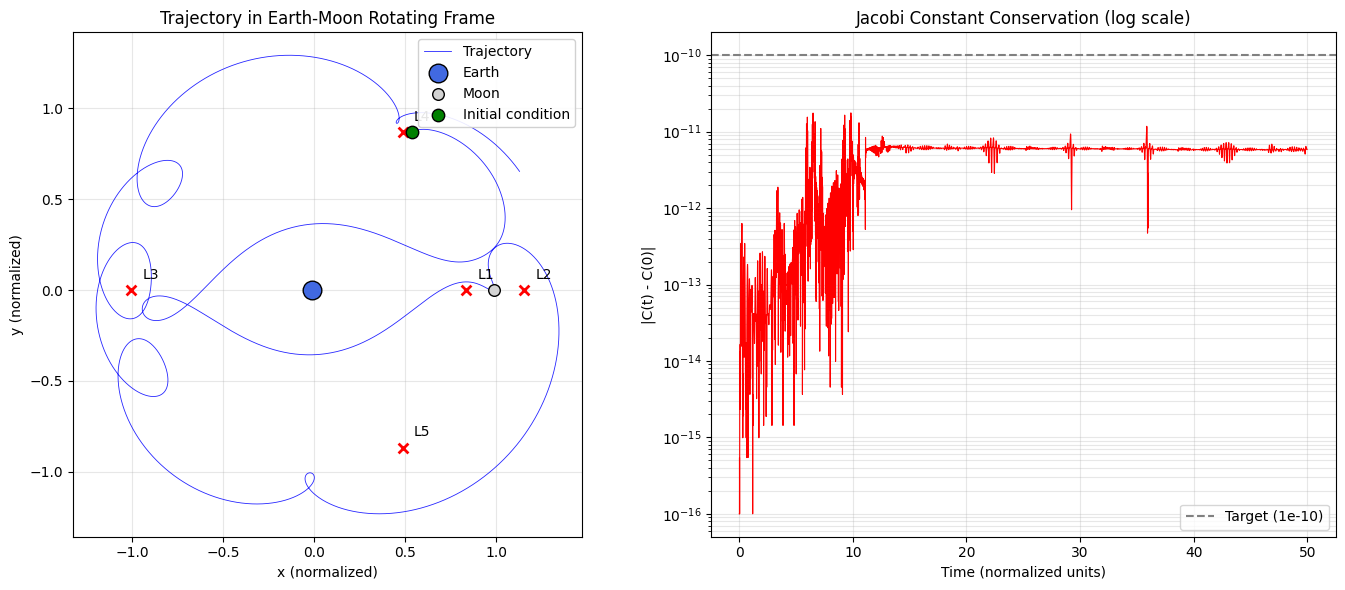

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax1, ax2 = axes

# Trajectory plot
ax1.plot(sol.y[0], sol.y[1], 'b-', linewidth=0.6, alpha=0.85, label='Trajectory')
ax1.scatter([-mu], [0], color='royalblue', s=180, label='Earth', zorder=5, edgecolor='black')
ax1.scatter([1 - mu], [0], color='lightgray', s=70, label='Moon', zorder=5, edgecolor='black')

for name, (lx, ly) in lps.items():
    ax1.scatter([lx], [ly], color='red', s=50, marker='x', zorder=5, linewidth=2)
    ax1.annotate(name, (lx, ly), textcoords='offset points', xytext=(8, 8), fontsize=10)

ax1.scatter([x0], [y0], color='green', s=80, marker='o', zorder=6,
            label='Initial condition', edgecolor='black')

ax1.set_aspect('equal')
ax1.set_xlabel('x (normalized)')
ax1.set_ylabel('y (normalized)')
ax1.set_title('Trajectory in Earth-Moon Rotating Frame')
ax1.legend(loc='upper right', framealpha=0.9)
ax1.grid(True, alpha=0.3)

# Jacobi conservation plot
ax2.semilogy(sol.t, deviation + 1e-16, 'r-', linewidth=0.8)
ax2.axhline(TARGET, color='gray', linestyle='--', label=f'Target ({TARGET:.0e})')
ax2.set_xlabel('Time (normalized units)')
ax2.set_ylabel('|C(t) - C(0)|')
ax2.set_title('Jacobi Constant Conservation (log scale)')
ax2.grid(True, alpha=0.3, which='both')
ax2.legend()

plt.tight_layout()
plt.show()

## 7. Checkpoint — what's working

If everything ran cleanly, you now have:

- ✅ CR3BP equations of motion in the rotating frame
- ✅ Jacobi constant computation
- ✅ All five Lagrange points located via root-finding
- ✅ High-accuracy ODE integration (DOP853, tolerances 1e-12)
- ✅ Energy-conservation validation passing at ~1e-11

This is a *clean baseline*. Commit this to your GitHub repo before extending it. From here on, every change should be a discrete commit.

---

## 8. Your TODOs — the path from here to QPITs

The next 20 weeks of work are building from this baseline up through the ladder to QPIT identification with ML. Here are the immediate extensions you'll work on. Do them in order — each builds on the previous.

### Week 2 — Solidify the foundation

- [ ] **TODO 1 — Stress test the integrator.** Try ICs near each Lagrange point and near Earth/Moon with various velocities. For each, check Jacobi conservation. You should find ICs where conservation degrades much faster than others — that's chaos showing up at the numerical level. Document what you find in your research log.
- [ ] **TODO 2 — Plot the zero-velocity curves (Hill regions).** These are the level sets of $\Omega(x,y) = C/2$. They define which regions of phase space are accessible at a given Jacobi constant. Beautiful and useful figures — and critical for understanding which Jacobi values give which orbital realm structures.
- [ ] **TODO 3 — Pick three Jacobi values** corresponding to qualitatively different access: (a) only Earth realm, (b) Earth + Moon realms connected via L1 neck, (c) all realms open. Plot zero-velocity curves for each.

### Week 3 — Become a real module

- [ ] **TODO 4 — Refactor into `src/cr3bp.py`.** Move the integrator, Jacobi function, and Lagrange points into a proper Python module with docstrings and a few basic tests in `tests/`. The notebook should `import cr3bp` rather than redefining functions.
- [ ] **TODO 5 — Implement the State Transition Matrix (STM).** The STM satisfies $\dot{\Phi}(t,t_0) = A(t)\Phi(t,t_0)$ where $A$ is the Jacobian of the right-hand side. You'll integrate it alongside the state, expanding the integrated vector from 4 components (state) to 4 + 16 = 20 components (state + STM). This is essential infrastructure: it's what the differential corrector and the eventual QPIT computation will both rely on. Do this *with* your dad in a weekly session.

### Week 4–6 — Periodic orbits and manifolds

- [ ] **TODO 6 — Single-shooting differential corrector** for finding L1 Lyapunov orbits. Use published initial conditions from Howell 1984 as warm starts. Convergence criterion: the orbit closes on itself to ~$10^{-10}$.
- [ ] **TODO 7 — Family continuation** to generate L1 and L2 Lyapunov orbit families across Jacobi constants.
- [ ] **TODO 8 — Halo orbits** (3D extension of Lyapunov orbits).
- [ ] **TODO 9 — Invariant manifolds** of periodic orbits. Compute monodromy matrices, eigendecompose, perturb along stable/unstable directions, integrate.

### Week 7–10 — The hard part: QPITs

- [ ] **TODO 10 — Implement Fourier-Galerkin discretization** of the invariance equation, following Olikara 2016 Chapter 3.
- [ ] **TODO 11 — Compute your first QPIT** using your chosen method. This is the make-or-break moment of the project.
- [ ] **TODO 12 — Family continuation of QPITs** across Jacobi constants and rotation numbers.

### Week 10–13 — ML

- [ ] **TODO 13 — Dataset generation on Titan** — many QPITs, labeled, ready for training.
- [ ] **TODO 14 — Baseline MLP classifier** in PyTorch.
- [ ] **TODO 15 — Phase-space-resolved failure analysis** — the central figure of your paper.

---

## 9. Research log entry template

Open your `docs/research_log.md` and add today's entry. Suggested format:

```
## YYYY-MM-DD

**Worked on:** [what you did]

**Key wins:**
- [thing that worked]
- [thing you learned]

**Stuck on / questions:**
- [thing that didn't work]
- [thing you don't yet understand]

**Next session:**
- [concrete next action — not "keep working" but a specific task]
```

This log is your evidence trail for STS. Daily entries, even short ones. The judges read the journey, not just the destination.